In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## Загрузка данных

In [15]:
df = pd.read_csv("/Users/nasy/Documents/ml_lr/ml_labs_mai/Classification/data/Titanic-Dataset.csv")

display(df.head())
print(df.shape)
df.info()
df.columns

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

## EDA

In [20]:
missing = pd.DataFrame({'Пропусков': df.isna().sum(), 'Доля, %': (df.isna().mean()*100).round(1)})
display(missing.sort_values('Пропусков', ascending=False))

print('Полных дубликатов:', df.duplicated().sum())
print('Дубликатов PassengerId:', df['PassengerId'].duplicated().sum())

print(df['Survived'].value_counts())
pd.crosstab(df['Survived'], df['Sex'])

,Пропусков,"Доля, %"
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2
PassengerId,0,0.0
Survived,0,0.0
Pclass,0,0.0
Name,0,0.0
Sex,0,0.0
SibSp,0,0.0
Parch,0,0.0


Полных дубликатов: 0
Дубликатов PassengerId: 0
Survived
0    549
1    342
Name: count, dtype: int64


Sex,female,male
Survived,,
0,81,468
1,233,109


Выживаемость среди женщин составила 74,2%, а среди мужчин 18,9%. Что говорит о том, что выживаемость среди женщин гораздо больше, чем мужчин.

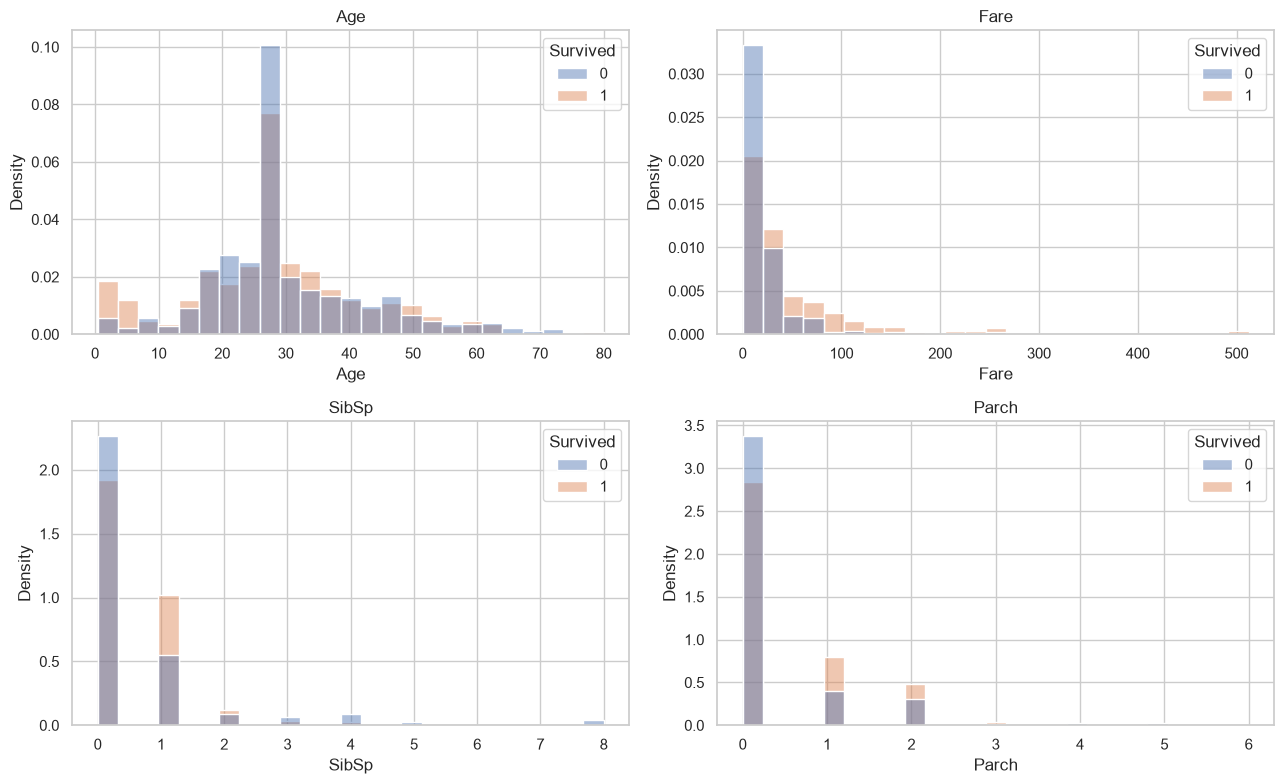

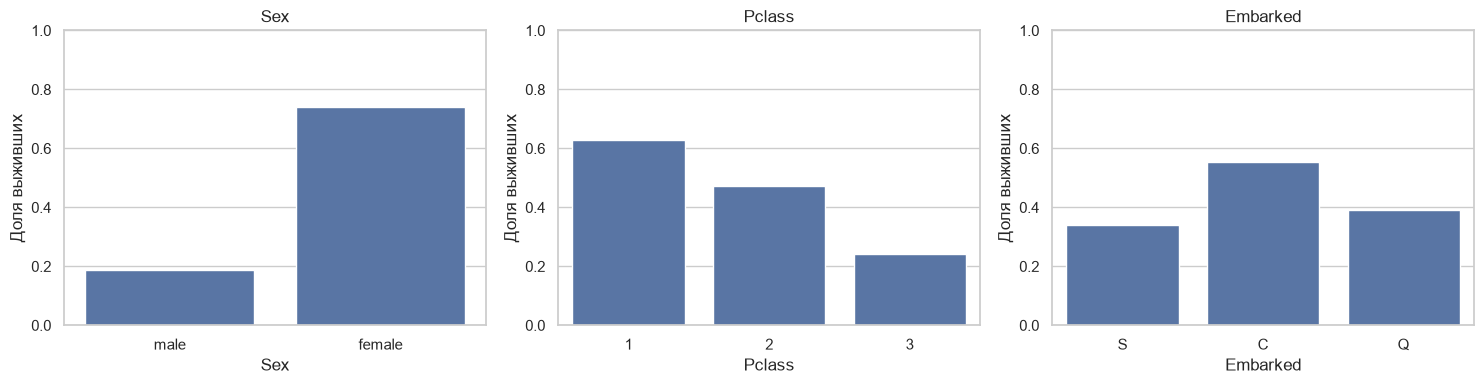

In [43]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue='Survived', stat='density',
                 common_norm=False, alpha=0.45, bins=25, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Sex', 'Pclass', 'Embarked']):
    sns.barplot(data=df, x=col, y='Survived', errorbar=None, ax=ax)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Доля выживших')
    ax.set_title(col)
plt.tight_layout()
plt.show()

,Количество,Доля выживших
Title,,
Master,40,0.575000
Miss,182,0.697802
Mr,517,0.156673
Mrs,125,0.792000
Rare,27,0.444444


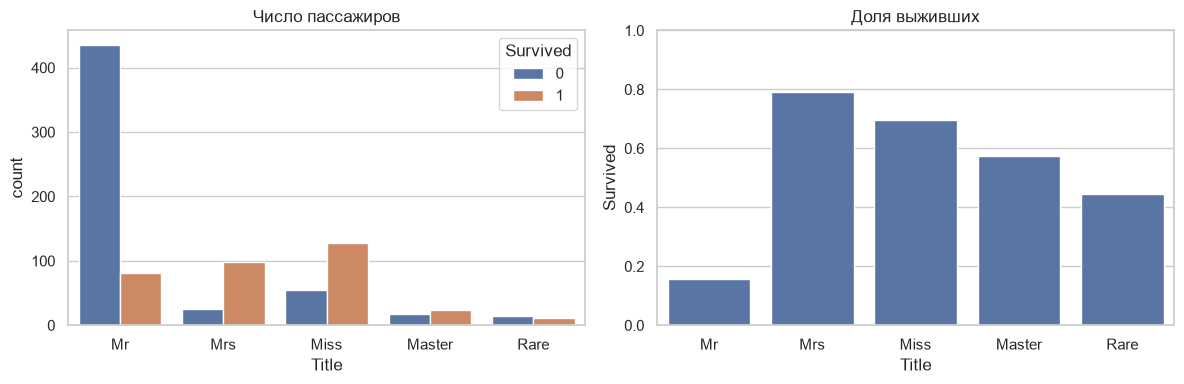

In [42]:
# Например: "Braund, Mr. Owen Harris" -> "Mr"
df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.')[0].str.strip()
# Редкие обращения объединяем по заранее заданному правилу, не используя Survived
df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

title_stats = df.groupby('Title')['Survived'].agg(['count', 'mean'])
display(title_stats.rename(columns={'count': 'Количество', 'mean': 'Доля выживших'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Title', hue='Survived', ax=axes[0])
sns.barplot(data=df, x='Title', y='Survived', errorbar=None, ax=axes[1])
axes[0].set_title('Число пассажиров')
axes[1].set_title('Доля выживших')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

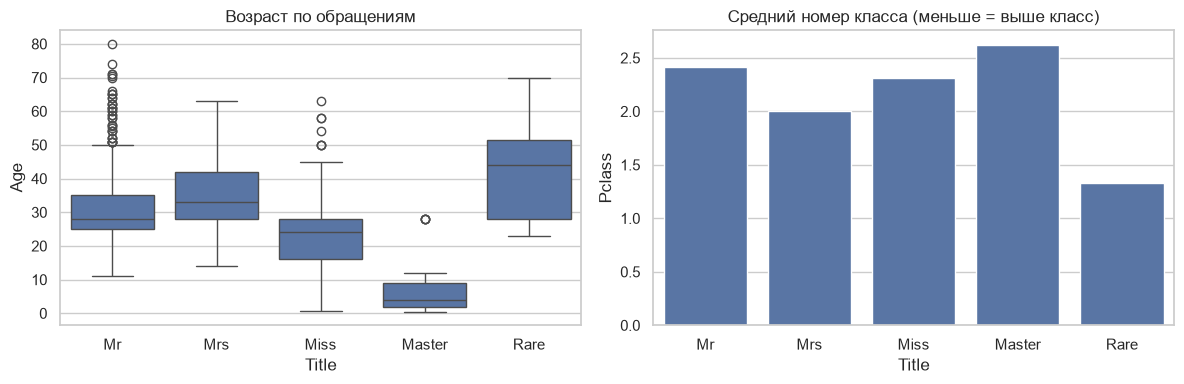

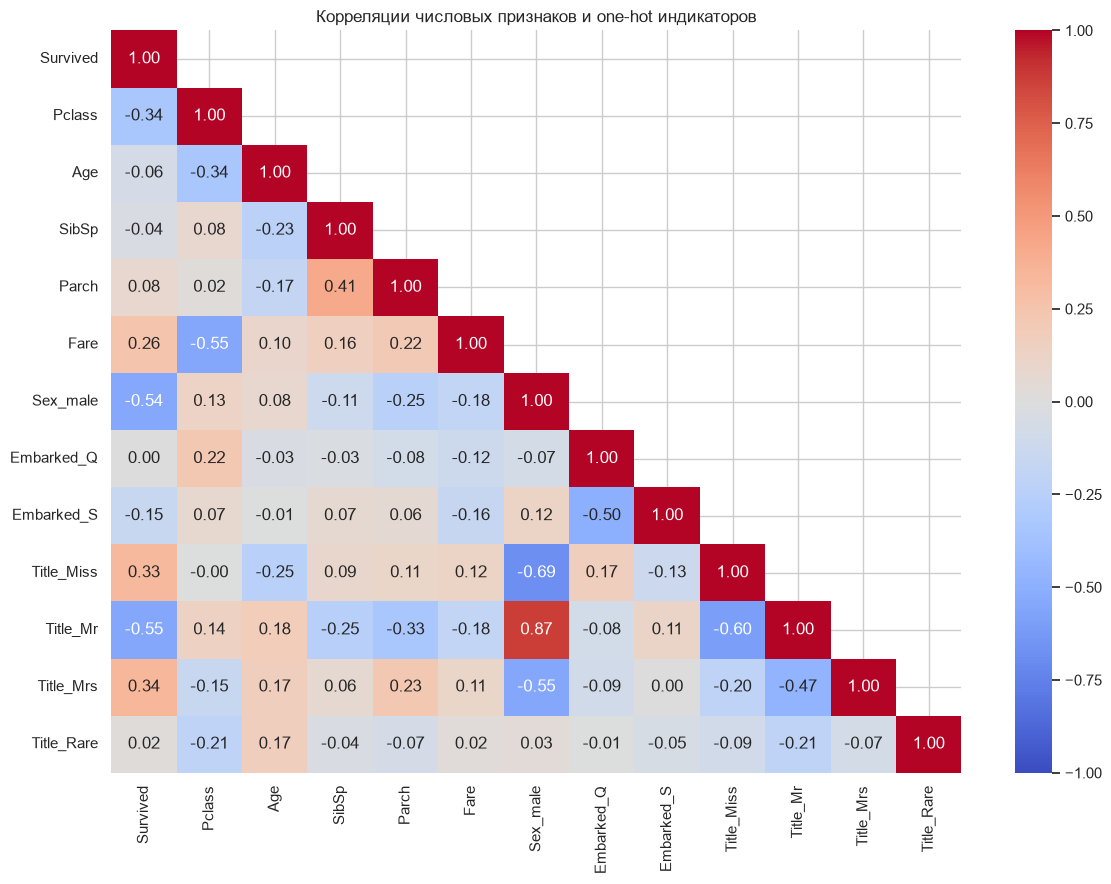

,corr(Survived)
Title_Mr,-0.549199
Sex_male,-0.543351
Pclass,-0.338481
Embarked_S,-0.149683
Age,-0.064910
SibSp,-0.035322
Embarked_Q,0.003650
Title_Rare,0.022030
Parch,0.081629
Fare,0.257307


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='Title', y='Age', ax=axes[0])
sns.barplot(data=df, x='Title', y='Pclass', errorbar=None, ax=axes[1])
axes[0].set_title('Возраст по обращениям')
axes[1].set_title('Средний номер класса (меньше = выше класс)')
plt.tight_layout()
plt.show()

corr_data = pd.get_dummies(
    df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title']],
    columns=['Sex', 'Embarked', 'Title'], drop_first=True, dtype=int
)
corr = corr_data.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляции числовых признаков и one-hot индикаторов')
plt.tight_layout()
plt.show()

display(corr['Survived'].drop('Survived').sort_values().to_frame('corr(Survived)'))

In [102]:
display(pd.crosstab(df['Survived'], df['Pclass']))
pd.crosstab(df["Pclass"], df["Survived"], normalize="index") * 100

Pclass,1,2,3
Survived,,,
0,80,97,372
1,136,87,119


Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


Можно наблюдать, что выживаемость среди пассажиров 1 класса выше невыживаемости, для второго класса распределена равномерно, а для третьего класса горажно меньше невыживаемости

In [103]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.028233
1    28.291433
Name: Age, dtype: float64

In [104]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df["Cabin"] = df["Cabin"].fillna("Unknown")

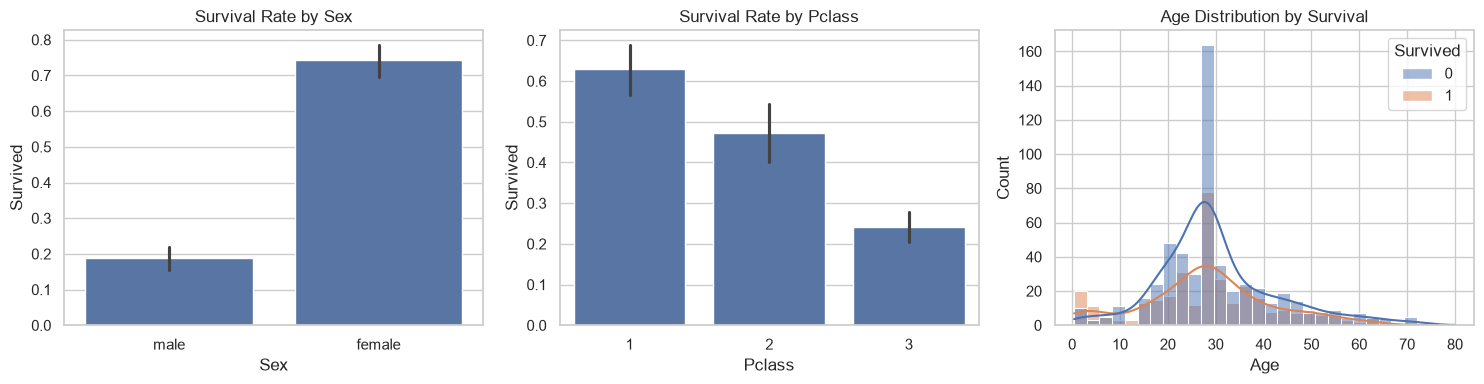

In [105]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.barplot(x='Sex', y='Survived', data=df)
plt.title('Survival Rate by Sex')

plt.subplot(1, 3, 2)
sns.barplot(x='Pclass', y='Survived', data=df)
plt.title('Survival Rate by Pclass')

plt.subplot(1, 3, 3)
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30)
plt.title('Age Distribution by Survival')

plt.tight_layout()
plt.show()

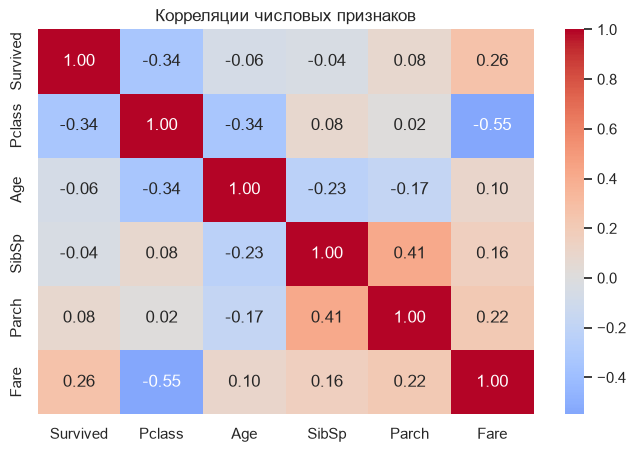

,index,FamilySize,mean,count
0,0,1,0.303538,537
1,1,2,0.552795,161
2,2,3,0.578431,102
3,3,4,0.724138,29
4,4,5,0.200000,15
5,5,6,0.136364,22
6,6,7,0.333333,12
7,7,8,0.000000,6
8,8,11,0.000000,7


In [106]:
numeric_eda = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
plt.figure(figsize=(8, 5))
sns.heatmap(df[numeric_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции числовых признаков')
plt.show()

eda_family = df.assign(FamilySize=df['SibSp'] + df['Parch'] + 1)
family_plot = eda_family.groupby('FamilySize', as_index=False)['Survived'].agg(['mean', 'count']).reset_index()
display(family_plot)

**Выводы после EDA:**

- Accuracy недостаточно, тк распределение классов неравномерно: выживших почти в 2 раза больше
- Более высокая выживаемость у женщин, у первого класса и среднего возраста(28-30)
- Пропуски в 'Age' заполнены 

**Что исключаем:** `PassengerId` — идентификатор; `Name`, `Ticket`, `Cabin` — потенциальные высококардинальные идентифицирующие признаки. `Survived` — цель, а не входной признак. Исключение колонок — консервативное решение для честной интерпретации, хотя из некоторых из них можно было бы аккуратно извлекать информативные признаки.

In [107]:
df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.')[0].str.strip()
display(df['Title'].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [108]:
title_counts = df['Title'].value_counts()

df['Title_grouped'] = df['Title'].where(
    df['Title'].map(title_counts) >= 10,
    'Rare'
)

display(
    df.groupby('Title_grouped')['Survived']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

,count,mean
Title_grouped,,
Mrs,125,0.792000
Miss,182,0.697802
Master,40,0.575000
Rare,27,0.444444
Mr,517,0.156673


##  train/test и predprocessing

In [109]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title']
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доля класса 1:', round(y_train.mean(), 3), round(y_test.mean(), 3))

num_features = ['Age', 'SibSp', 'Parch', 'Fare']
cat_features = ['Pclass', 'Sex', 'Embarked', 'Title']

numeric = Pipeline([
    ('missing', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
categorical = Pipeline([
    ('missing', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric, num_features),
    ('cat', categorical, cat_features)
])

Train: (712, 8) Test: (179, 8)
Доля класса 1: 0.383 0.385


In [110]:
results = []

## Dummy Classifier — baseline

,Model,Accuracy,Precision,Recall,F1
0,Dummy,0.617,0.0,0.0,0.0


,Predicted 0,Predicted 1
0,439,0
1,273,0


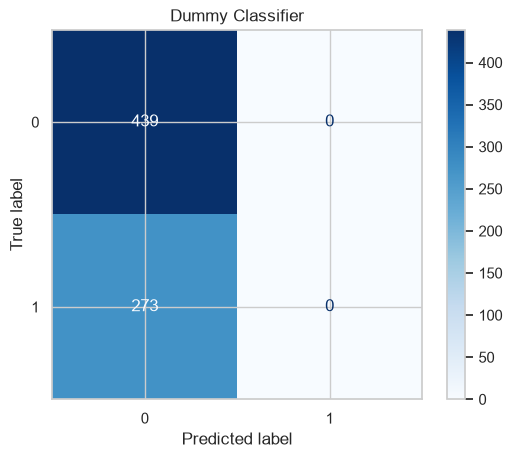

In [111]:
dummy = DummyClassifier(strategy='most_frequent')

pred = cross_val_predict(dummy, X_train, y_train, cv=cv)

dummy_metrics = pd.DataFrame([{
    'Model': 'Dummy',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred, zero_division=0),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(dummy_metrics.round(3))

results.append(dummy_metrics.iloc[0].to_dict())

tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=[' 0', ' 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('Dummy Classifier')
plt.show()

## Linear Regression

In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logreg = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

params = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

grid_logreg = GridSearchCV(
    logreg,
    params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_logreg.fit(X_train, y_train)

print('Лучшие параметры:', grid_logreg.best_params_)
print('Лучший CV F1:', round(grid_logreg.best_score_, 3))

Лучшие параметры: {'model__C': 100, 'model__class_weight': None}
Лучший CV F1: 0.761


In [113]:
logreg = grid_logreg.best_estimator_

pred = cross_val_predict(logreg, X_train, y_train, cv=cv)

logreg_metrics = pd.DataFrame([{
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(logreg_metrics.round(3))

results.append(logreg_metrics.iloc[1].to_dict())

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('Logistic Regression')
plt.show()

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.82,0.778,0.744,0.76


IndexError: single positional indexer is out-of-bounds

In [ ]:
logreg.fit(X_train, y_train)

train_f1 = f1_score(y_train, logreg.predict(X_train))
cv_f1 = f1_score(y_train, pred)

print(f'Train F1: {train_f1:.3f}')
print(f'CV F1: {cv_f1:.3f}')
print(f'Разница: {train_f1 - cv_f1:.3f}')

Train F1: 0.772
CV F1: 0.758
Разница: 0.014


## Random Forest

In [ ]:
from sklearn.model_selection import GridSearchCV

forest = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

params = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [5, 10, 15, None],
    'model__min_samples_leaf': [1, 2, 5],
    'model__max_features': ['sqrt', 'log2']
}

grid_forest = GridSearchCV(
    forest,
    params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_forest.fit(X_train, y_train)

print('Лучшие параметры:', grid_forest.best_params_)
print('Лучший CV F1:', round(grid_forest.best_score_, 3))

Лучшие параметры: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Лучший CV F1: 0.754


In [ ]:
forest_cv = pd.DataFrame(grid_forest.cv_results_)

display(
    forest_cv[
        ['param_model__n_estimators',
         'param_model__max_depth',
         'param_model__min_samples_leaf',
         'param_model__max_features',
         'mean_test_score']
    ]
    .sort_values('mean_test_score', ascending=False)
    .head(10)
    .round(3)
)

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_score
18,100,10,1,sqrt,0.754
27,100,10,1,log2,0.754
1,200,5,1,sqrt,0.754
10,200,5,1,log2,0.754
28,200,10,1,log2,0.753
19,200,10,1,sqrt,0.753
14,300,5,2,log2,0.753
5,300,5,2,sqrt,0.753
38,300,15,1,sqrt,0.752
47,300,15,1,log2,0.752


,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.819,0.786,0.725,0.754


,Predicted 0,Predicted 1
Actual 0,385,54
Actual 1,75,198


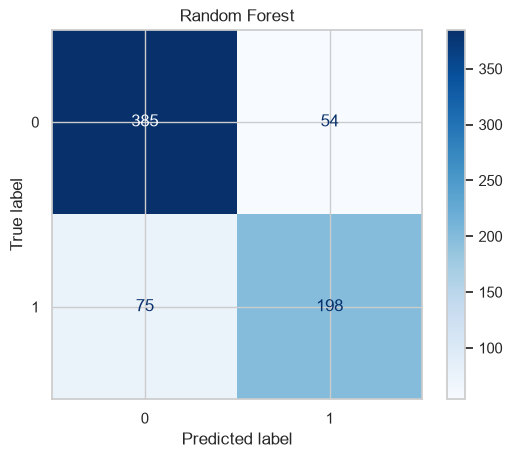

In [ ]:
forest = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=42
    ))
])

pred = cross_val_predict(forest, X_train, y_train, cv=cv)

forest_metrics = pd.DataFrame([{
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(forest_metrics.round(3))

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('Random Forest')
plt.show()

In [ ]:
forest.fit(X_train, y_train)

train_pred = forest.predict(X_train)

print('Train F1:', round(f1_score(y_train, train_pred), 3))
print('CV F1:', round(f1_score(y_train, pred), 3))

Train F1: 0.929
CV F1: 0.754


переобучение, попробуем сильнее регуляризировать

In [ ]:
params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5, 7],
    'model__min_samples_leaf': [2, 5, 10],
    'model__min_samples_split': [5, 10]
}

grid_forest = GridSearchCV(
    forest,
    params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_forest.fit(X_train, y_train)

print('Лучшие параметры:', grid_forest.best_params_)
print('Лучший CV F1:', round(grid_forest.best_score_, 3))

Лучшие параметры: {'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Лучший CV F1: 0.757


,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.82,0.784,0.733,0.758


,Predicted 0,Predicted 1
Actual 0,384,55
Actual 1,73,200


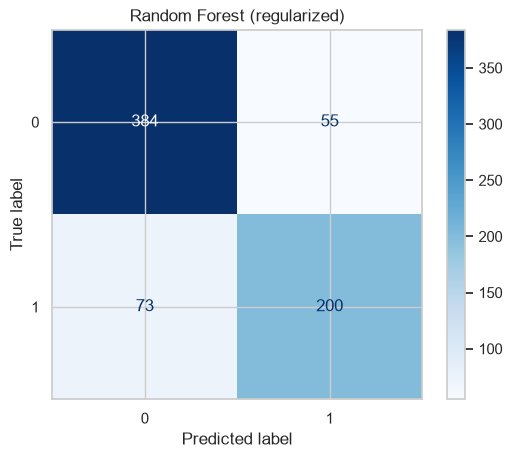

In [ ]:
forest = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        min_samples_split=5,
        random_state=42
    ))
])

pred = cross_val_predict(forest, X_train, y_train, cv=cv)

forest_metrics = pd.DataFrame([{
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(forest_metrics.round(3))

results.append(forest_metrics.iloc[2].to_dict())

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('Random Forest (regularized)')
plt.show()

In [ ]:
forest.fit(X_train, y_train)

train_f1 = f1_score(y_train, forest.predict(X_train))
cv_f1 = f1_score(y_train, pred)

print(f'Train F1: {train_f1:.3f}')
print(f'CV F1: {cv_f1:.3f}')
print(f'Разница: {train_f1 - cv_f1:.3f}')

Train F1: 0.762
CV F1: 0.758
Разница: 0.004


переобучения нет



## Gradient Boosting

In [114]:
catboost = Pipeline([
    ('prep', preprocessor),
    ('model', CatBoostClassifier(verbose=0, random_seed=42))
])

params = {
    'model__iterations': [200, 400, 600],
    'model__depth': [3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.1],
    'model__l2_leaf_reg': [3, 5, 10]
}

grid_catboost = GridSearchCV(
    catboost,
    params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_catboost.fit(X_train, y_train)

print('Лучшие параметры:', grid_catboost.best_params_)
print('Лучший CV F1:', round(grid_catboost.best_score_, 3))

Лучшие параметры: {'model__depth': 3, 'model__iterations': 400, 'model__l2_leaf_reg': 5, 'model__learning_rate': 0.1}
Лучший CV F1: 0.787


In [115]:
catboost = grid_catboost.best_estimator_

pred = cross_val_predict(catboost, X_train, y_train, cv=cv)

catboost_metrics = pd.DataFrame([{
    'Model': 'CatBoost',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(catboost_metrics.round(3))
results.append(catboost_metrics.iloc[3].to_dict())

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('CatBoost')
plt.show()

catboost.fit(X_train, y_train)

print('Train F1:', round(f1_score(y_train, catboost.predict(X_train)), 3))
print('CV F1:', round(f1_score(y_train, pred), 3))

,Model,Accuracy,Precision,Recall,F1
0,CatBoost,0.843,0.821,0.755,0.786


IndexError: single positional indexer is out-of-bounds

## SVM

In [ ]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

In [ ]:
svm = SVC()

params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.01, 0.1, 1]
}

grid_svm = GridSearchCV(
    svm, params, cv=cv, scoring='f1', n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)

print('Лучшие параметры:', grid_svm.best_params_)
print('Лучший CV F1:', round(grid_svm.best_score_, 3))

Лучшие параметры: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Лучший CV F1: 0.768


,Model,Accuracy,Precision,Recall,F1
0,SVM,0.83,0.806,0.733,0.768


,Predicted 0,Predicted 1
Actual 0,391,48
Actual 1,73,200


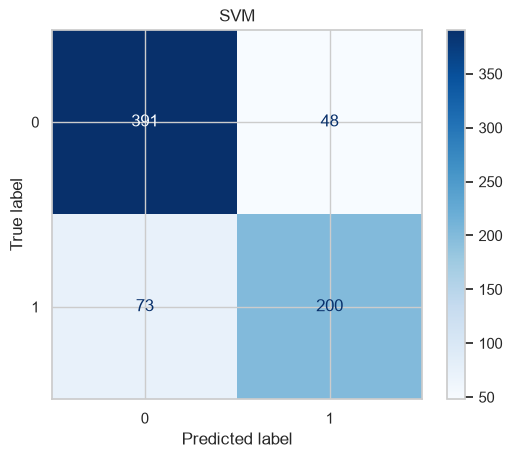

In [ ]:
svm = grid_svm.best_estimator_

pred = cross_val_predict(svm, X_train_scaled, y_train, cv=cv)

svm_metrics = pd.DataFrame([{
    'Model': 'SVM',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(svm_metrics.round(3))
results.append(svm_metrics.iloc[4].to_dict())

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('SVM')
plt.show()

## KNN

In [ ]:
knn = KNeighborsClassifier()

params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

grid_knn = GridSearchCV(
    knn, params, cv=cv, scoring='f1', n_jobs=-1
)

grid_knn.fit(X_train_scaled, y_train)

print('Лучшие параметры:', grid_knn.best_params_)
print('Лучший CV F1:', round(grid_knn.best_score_, 3))

Лучшие параметры: {'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}
Лучший CV F1: 0.76


,Model,Accuracy,Precision,Recall,F1
0,KNN,0.826,0.804,0.722,0.761


,Predicted 0,Predicted 1
Actual 0,391,48
Actual 1,76,197


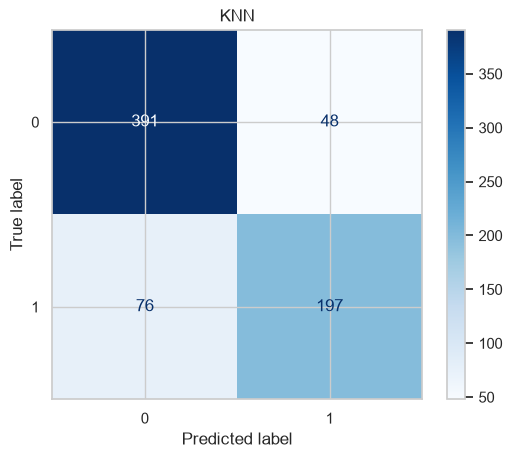

In [ ]:
knn = grid_knn.best_estimator_

pred = cross_val_predict(knn, X_train_scaled, y_train, cv=cv)

knn_metrics = pd.DataFrame([{
    'Model': 'KNN',
    'Accuracy': accuracy_score(y_train, pred),
    'Precision': precision_score(y_train, pred),
    'Recall': recall_score(y_train, pred),
    'F1': f1_score(y_train, pred)
}])

display(knn_metrics.round(3))
results.append(knn_metrics.iloc[5].to_dict())

cm = pd.DataFrame(
    confusion_matrix(y_train, pred),
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

display(cm)

ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap='Blues')
plt.title('KNN')
plt.show()

## Итог

In [ ]:
results = pd.DataFrame(results)
display(results.round(3))

,0,1,2,3,4
0,Dummy,0.616573,0.0,0.0,0.0
1,Dummy,0.616573,0.0,0.0,0.0
2,Dummy,0.616573,0.0,0.0,0.0
3,Model,Accuracy,Precision,Recall,F1
4,Model,Accuracy,Precision,Recall,F1
5,Model,Accuracy,Precision,Recall,F1
6,Model,Accuracy,Precision,Recall,F1
7,Model,Accuracy,Precision,Recall,F1
8,Model,Accuracy,Precision,Recall,F1
9,Model,Accuracy,Precision,Recall,F1
